# 4 · How well do the estimates reproduce the measured flux?

## Why not simply the RMSE?

Most measured fluxes are within a few W m⁻² of zero (Chapter 1). An estimate that is *always close to zero* then has a
small RMSE although it contains no information. The table below shows exactly this: the ERA5-only bulk flux has the
**smallest** centred RMSE of all estimates — and at the same time the smallest amplitude and the lowest correlation.

The paper therefore uses two separate measures:

* **slope $b$** of the regression of the estimate on the EC flux — the fraction of the observed *amplitude* that is recovered (ideal: 1),
* **correlation $r$** — whether the estimate is large where the measurement is large (ideal: 1).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
REPO = Path("..").resolve(); sys.path.insert(0, str(REPO))
plt.rcParams.update({"figure.dpi": 110, "figure.constrained_layout.use": True, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

AR  = REPO / "data/observations/ar"
FIG = xr.open_dataset(REPO / "data/model_output/sensitivity_figure_data.nc")      # all flux estimates, 91 segments
SEG = xr.open_dataset(AR / "analysis_ready_polar6_turbulent_fluxes_latest_5km.nc").sel(start_time=FIG.start_time.values)
EC  = FIG["H_obs_ec"].values

from fluxpy.sensitivity import skill_metrics
import logging; logging.disable(logging.INFO)
NAMES = {"H_obs_bulk": "H_S,obs,bulk  (measured inputs)", "H_rs_bulk": "H_S,RS,bulk   (MODIS + ERA5)",
         "H_era_bulk": "H_S,ERA,bulk  (ERA5 only)", "H_era_diag": "H_S,ERA,diag  (ERA5's own flux)", "H_car_diag": "H_S,CAR,diag  (CARRA's own flux)"}
rows = {}
for key, name in NAMES.items():
    m = skill_metrics(EC, FIG[key].values, key)
    rows[name] = {"slope b": m["slope"], "r": m["r"], "bias (W m-2)": m["bias"], "centred RMSE (W m-2)": m["crmse"], "n": m["n"]}
pd.DataFrame(rows).T.round(1)

,slope b,r,bias (W m-2),centred RMSE (W m-2),n
"H_S,obs,bulk (measured inputs)",1.6,0.7,2.2,6.2,91.0
"H_S,RS,bulk (MODIS + ERA5)",0.7,0.5,-1.5,4.4,91.0
"H_S,ERA,bulk (ERA5 only)",0.2,0.3,-3.5,3.6,91.0
"H_S,ERA,diag (ERA5's own flux)",1.2,0.6,-2.8,6.1,91.0
"H_S,CAR,diag (CARRA's own flux)",1.2,0.6,-3.6,6.6,73.0


(CARRA is not available on 13 April, hence the smaller *n*.)

## The three bulk estimates against the reference (Fig. 5)

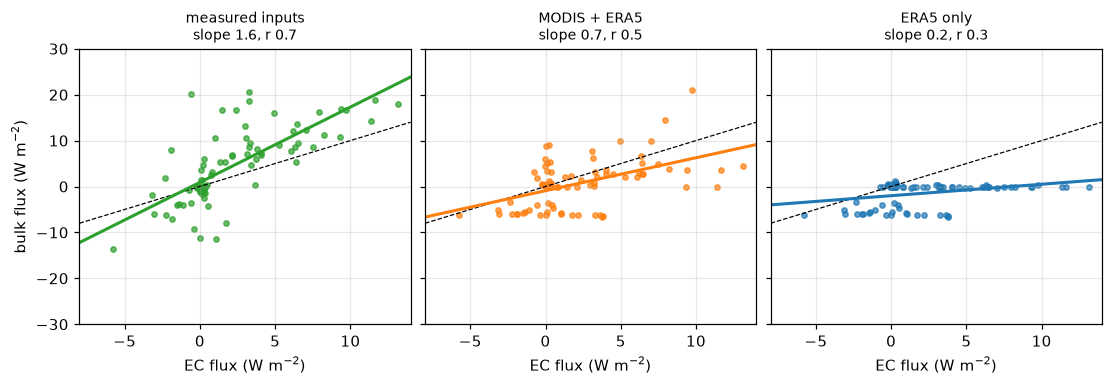

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(10, 3.4), sharex=True, sharey=True)
for ax, key, c in zip(axs, ["H_obs_bulk", "H_rs_bulk", "H_era_bulk"], ["C2", "C1", "C0"]):
    h = FIG[key].values; ok = np.isfinite(EC) & np.isfinite(h); b, a = np.polyfit(EC[ok], h[ok], 1)
    ax.scatter(EC[ok], h[ok], s=12, color=c, alpha=0.7); xx = np.array([-8, 14])
    ax.plot(xx, xx, "k--", lw=0.8); ax.plot(xx, a + b * xx, color=c, lw=2)
    ax.set_title(f"{NAMES[key].split('(')[1][:-1]}\nslope {b:.1f}, r {np.corrcoef(EC[ok], h[ok])[0, 1]:.1f}", fontsize=9)
    ax.set_xlabel("EC flux (W m$^{-2}$)"); ax.set_xlim(-8, 14); ax.set_ylim(-30, 30)
axs[0].set_ylabel("bulk flux (W m$^{-2}$)");

Reading the three panels from right to left is reading the paper's main result:

* **ERA5 only** — the points lie on an almost horizontal line: only about a quarter of the amplitude is recovered and the correlation is weak.
* **MODIS surface temperature instead of ERA5's** — the amplitude rises to about 70 %, the correlation improves.
* **measured inputs** — the best correlation, but now the amplitude is *over*estimated (slope well above 1).
  With correct inputs the conventional transfer coefficient is too large; Chapter 5 follows this up.

## Where does the satellite surface temperature help?

If the benefit of MODIS comes from resolving leads and thin ice that ERA5 cannot see, it should be concentrated on
segments with a *heterogeneous* surface. The segments are split at the median of the within-segment standard
deviation of the KT-19 surface temperature.

In [3]:
sd = SEG.T_sfc_std.values; rs, era = FIG.H_rs_bulk.values, FIG.H_era_bulk.values
ok = np.isfinite(EC) & np.isfinite(rs) & np.isfinite(era) & np.isfinite(sd); med = np.median(sd[ok])
rows = {}
for label, m in (("heterogeneous half", ok & (sd > med)), ("homogeneous half", ok & (sd <= med))):
    rows[label] = {"n": int(m.sum()), "r  ERA5 only": np.corrcoef(EC[m], era[m])[0, 1], "r  with MODIS": np.corrcoef(EC[m], rs[m])[0, 1],
                   "slope  ERA5 only": np.polyfit(EC[m], era[m], 1)[0], "slope  with MODIS": np.polyfit(EC[m], rs[m], 1)[0]}
print(f"median within-segment standard deviation of the surface temperature: {med:.1f} K"); pd.DataFrame(rows).T.round(1)

median within-segment standard deviation of the surface temperature: 1.2 K


,n,r ERA5 only,r with MODIS,slope ERA5 only,slope with MODIS
heterogeneous half,45.0,-0.4,0.5,-0.0,0.5
homogeneous half,46.0,0.3,0.4,0.3,0.5


**Take-away.** The surface temperature decides whether a bulk estimate follows the observed variability.
ERA5's surface temperature cannot represent leads and thin ice inside a grid cell; on heterogeneous segments its flux
is even anti-correlated with the measurement, and this is where replacing it by the MODIS surface temperature changes the most.